# Deep Learning for Perception Assignment 2, Section B 
# 23F-0608 Muneeb Akbar
## Robust CIFAR-10 classification from only 500 training images

**Task.** Train an Inception-style CNN *from scratch* on 400 CIFAR-10 images (+100 for validation) so that it stays accurate on a **shifted** test set (rotation, brightness/contrast, blur, noise, occlusion and one hidden corruption).

**Rules respected in this notebook**

| Rule | How it is enforced |
|---|---|
| No pretrained weights | Model is randomly initialised |
| ≤ 1,000,000 trainable parameters | `assert` in the model cell |
| ≥ 1 Inception module | `InceptionModule` (1×1, 1×1→3×3, 1×1→5×5, pool→1×1) is used 3 times |
| Never tune on `shifted_test` / `clean_test` | All hyper-parameters, checkpoints and early stopping use the 100-image validation split only; test sets are evaluated once after training for reporting |
| Augmentation on the fly, train only | Transforms run inside the `Dataset.__getitem__`; nothing is pre-generated or saved |
| ≤ 60 epochs, fixed seed, 3 seeds | `MAX_EPOCHS = 60`, `RUN_SEEDS = [0, 1, 2]`, mean ± std reported |

> **About `shifted_test` and the hidden corruption.** `shifted_test` is built by a fixed, seeded pipeline: random rotation (up to ±25°), brightness and contrast changes, a random rectangular occlusion covering ≈ 25 % of the image, and **one additional hidden corruption**. The exact hidden corruption will be provided separately, so it is isolated in a single function, `hidden_corruption(...)` (cell 0.1). It currently contains a **stand-in** (random grayscale / RGB channel swap) so that the notebook runs end-to-end; **replace only the body of that function** (or set `PROVIDED_SHIFTED` to the official file) and re-run the notebook — nothing else has to change.
>
> **Seeds and splits** are documented in the *Reproducibility record* cell (printed and saved to `results/reproducibility.json`).

In [1]:
# ---------------------------------------------------------------- imports
import os, random, time, json, math, copy, itertools, warnings, platform
from dataclasses import dataclass, replace
from typing import Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision.transforms import v2 as T
import torchvision.transforms.v2.functional as TF

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# ---------------------------------------------------------------- configuration
GLOBAL_SEED   = 42            # fixes the 500-image subset, the 400/100 split and the shifted-test pipeline
RUN_SEEDS     = [0, 1, 2]     # 3 training seeds -> mean ± std
MAX_EPOCHS    = 60            # assignment maximum
BATCH_SIZE    = 32
PATIENCE      = 25            # early stopping (on validation accuracy)
N_SEARCH      = 8             # random-search trials for hyper-parameters (validation only)
QUICK_TEST    = False         # True -> tiny run (3 epochs, 1 seed) just to check that the notebook works
PROVIDED_SHIFTED = None       # e.g. "shifted_test.npz" with arrays x (N,3,32,32 uint8) and y (N,) if given by the instructor
SHIFT_SEED, HIDDEN_ONLY_SEED, DIAG_SEED = GLOBAL_SEED, GLOBAL_SEED + 1, GLOBAL_SEED + 2   # seeds of the shifted_test / hidden-only / diagnostic corruption pipelines
SHIFT_P_HIDDEN = 0.5          # probability that an image of shifted_test receives the hidden corruption
SHIFT_INCLUDE_BLUR_NOISE = False   # specified pipeline = rotation + brightness/contrast + occlusion + hidden (blur/noise only as extra diagnostics)

if QUICK_TEST:
    MAX_EPOCHS, RUN_SEEDS, N_SEARCH, PATIENCE = 3, [0], 2, 3

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
os.makedirs("results", exist_ok=True); os.makedirs("figures", exist_ok=True)

def set_seed(seed: int):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(GLOBAL_SEED)
print(f"python {platform.python_version()} | torch {torch.__version__} | torchvision {torchvision.__version__} | device = {device}")
print(f"GLOBAL_SEED={GLOBAL_SEED}  RUN_SEEDS={RUN_SEEDS}  MAX_EPOCHS={MAX_EPOCHS}  QUICK_TEST={QUICK_TEST}")

python 3.13.15 | torch 2.11.0+cu128 | torchvision 0.26.0+cu128 | device = cuda
GLOBAL_SEED=42  RUN_SEEDS=[0, 1, 2]  MAX_EPOCHS=60  QUICK_TEST=False


## 0. Data: `train_small`, validation split, `clean_test`
* `train_small`: 500 images, exactly 50 per class, drawn with a fixed seed from the CIFAR-10 training set.
* Stratified split of `train_small` → **400 train (40/class)** and **100 validation (10/class)**.
* `clean_test`: the original 10,000 CIFAR-10 test images (reporting only).

In [2]:
CLASSES = ["airplane","automobile","bird","cat","deer","dog","frog","horse","ship","truck"]

def load_cifar10(root="./data"):
    tr = torchvision.datasets.CIFAR10(root, train=True,  download=True)
    te = torchvision.datasets.CIFAR10(root, train=False, download=True)
    to_t = lambda a: torch.from_numpy(a).permute(0, 3, 1, 2).contiguous()          # NHWC uint8 -> NCHW uint8
    return to_t(tr.data), torch.tensor(tr.targets), to_t(te.data), torch.tensor(te.targets)

x_all, y_all, x_clean_test, y_test = load_cifar10()

rng = np.random.RandomState(GLOBAL_SEED)
small_idx, tr_idx, va_idx = [], [], []
for c in range(10):
    idx = rng.permutation(np.where(y_all.numpy() == c)[0])[:50]       # 50 images per class
    small_idx += idx.tolist(); tr_idx += idx[:40].tolist(); va_idx += idx[40:].tolist()

assert len(set(tr_idx) & set(va_idx)) == 0 and len(set(tr_idx) | set(va_idx)) == 500, "train/val must be disjoint and total 500"
x_train, y_train = x_all[tr_idx], y_all[tr_idx]
x_val,   y_val   = x_all[va_idx], y_all[va_idx]
print("train_small:", len(small_idx), "| train:", tuple(x_train.shape), "| val:", tuple(x_val.shape), "| clean_test:", tuple(x_clean_test.shape))
print("images / class  train:", torch.bincount(y_train).tolist(), " val:", torch.bincount(y_val).tolist())

# float copies of the (never augmented) train / val images, kept on the device for fast evaluation
x_train_f = (x_train.float() / 255).to(device); y_train_d = y_train.to(device)
x_val_f   = (x_val.float()   / 255).to(device); y_val_d   = y_val.to(device)

100%|██████████| 170M/170M [49:59<00:00, 56.8kB/s] 


train_small: 500 | train: (400, 3, 32, 32) | val: (100, 3, 32, 32) | clean_test: (10000, 3, 32, 32)
images / class  train: [40, 40, 40, 40, 40, 40, 40, 40, 40, 40]  val: [10, 10, 10, 10, 10, 10, 10, 10, 10, 10]


## 0.1 The shifted test set (corruption pipeline)
Every `clean_test` image is passed through a **fixed, seeded** pipeline (`SHIFT_SEED = 42`):

1. random rotation, uniform in **±25°**;
2. brightness (× U(0.4, 1.6)) and contrast (× U(0.5, 1.5)) change;
3. random solid rectangle covering **≈ 25 %** of the image (area U(0.20, 0.30), random aspect ratio and position);
4. the **hidden corruption** (`hidden_corruption(...)`, applied to each image with probability `SHIFT_P_HIDDEN = 0.5`; stand-in until the official one is released).

(Blur / noise are *not* part of `shifted_test` unless `SHIFT_INCLUDE_BLUR_NOISE = True`.) Per-image corruption parameters are logged in a metadata table for the error analysis.

The test sets are used **only for final reporting** never for training, validation, early stopping or hyper-parameter tuning (enforced by a guard in the code). I also build *single-corruption* versions of `clean_test` (reporting only) to show *which* augmentation fixes *which* corruption.

built 8 test sets in 18s: ['clean', 'shifted', 'hidden_only', 'rotation', 'bright/contrast', 'blur', 'noise', 'occlusion']


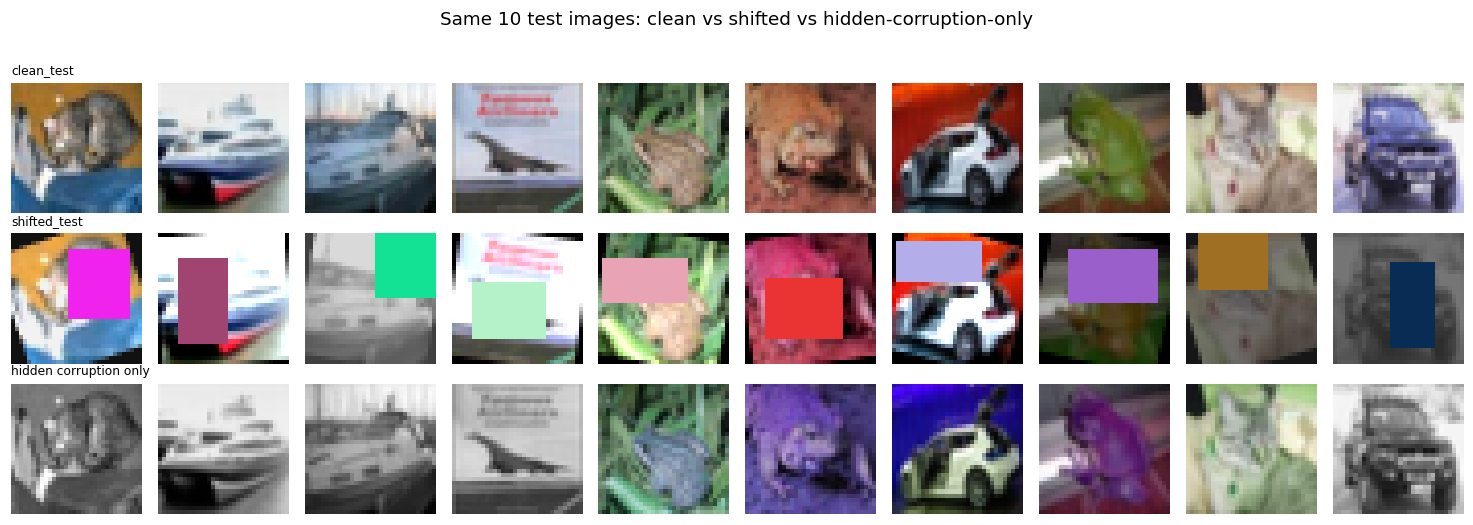

In [3]:
INTERP = T.InterpolationMode.BILINEAR
ALL_CORR = ("rot", "bc", "blur", "noise", "occ", "hidden")
_PERMS = [p for p in itertools.permutations(range(3)) if p != (0, 1, 2)]

def hidden_corruption(img, U):
    """HIDDEN CORRUPTION -- STAND-IN. Replace the body of this function with the official hidden corruption.
    img : float tensor (3, H, W) in [0, 1];  U(a, b): seeded uniform random draw (use it for ALL randomness -> reproducible).
    returns (corrupted float image, short label string used in the error analysis)."""
    if U(0, 1) < 0.5:
        return TF.rgb_to_grayscale(img, num_output_channels=3), "gray"
    perm = _PERMS[int(U(0, len(_PERMS) - 1e-6))]
    return img[list(perm)], "swap"

def corrupt_images(x_uint8, seed, enable=ALL_CORR, p_blur=0.5, p_noise=0.5, p_hidden=0.5):
    """Seeded, deterministic corruption pipeline. Returns (uint8 images, metadata DataFrame)."""
    g = torch.Generator().manual_seed(seed)
    U = lambda a, b: a + (b - a) * torch.rand(1, generator=g).item()
    N, _, H, W = x_uint8.shape
    out = torch.empty_like(x_uint8); meta = []
    for i in range(N):
        img = x_uint8[i].float() / 255.
        m = dict(angle=0., bright=1., contrast=1., blur=0., noise=0., occl=0., hidden="none")
        if "rot" in enable:
            m["angle"] = U(-25, 25); img = TF.rotate(img, m["angle"], interpolation=INTERP)
        if "bc" in enable:
            m["bright"], m["contrast"] = U(0.4, 1.6), U(0.5, 1.5)
            img = TF.adjust_contrast(TF.adjust_brightness(img, m["bright"]), m["contrast"])
        if "blur" in enable and U(0, 1) < p_blur:
            m["blur"] = U(0.6, 1.6); img = TF.gaussian_blur(img, [5, 5], [m["blur"], m["blur"]])
        if "noise" in enable and U(0, 1) < p_noise:
            m["noise"] = U(0.03, 0.10); img = img + torch.randn(img.shape, generator=g) * m["noise"]
        if "hidden" in enable and U(0, 1) < p_hidden:
            img, m["hidden"] = hidden_corruption(img.clamp(0, 1), U)
        if "occ" in enable:
            area = U(0.20, 0.30) * H * W; ar = math.exp(U(math.log(0.5), math.log(2.0)))
            h = min(H, int(round(math.sqrt(area * ar)))); w = min(W, int(round(math.sqrt(area / ar))))
            top = int(U(0, H - h + 1 - 1e-6)); left = int(U(0, W - w + 1 - 1e-6))
            img = img.clone(); img[:, top:top + h, left:left + w] = torch.rand(3, 1, 1, generator=g)
            m["occl"] = h * w / (H * W)
        out[i] = (img.clamp(0, 1) * 255).round().to(torch.uint8); meta.append(m)
    return out, pd.DataFrame(meta)

t0 = time.time()
TEST_SETS, TEST_META = {"clean": x_clean_test}, {}

if PROVIDED_SHIFTED and os.path.exists(PROVIDED_SHIFTED):
    d = np.load(PROVIDED_SHIFTED); TEST_SETS["shifted"] = torch.from_numpy(d["x"]); TEST_META["shifted"] = None
    print("Loaded provided shifted_test from", PROVIDED_SHIFTED)
else:
    SHIFT_ENABLE = ("rot", "bc", "occ", "hidden") + (("blur", "noise") if SHIFT_INCLUDE_BLUR_NOISE else ())
    TEST_SETS["shifted"], TEST_META["shifted"] = corrupt_images(x_clean_test, seed=SHIFT_SEED, enable=SHIFT_ENABLE, p_hidden=SHIFT_P_HIDDEN)

# hidden-corruption-only test (every image gets it) and single-corruption diagnostics (reporting only)
TEST_SETS["hidden_only"], TEST_META["hidden_only"] = corrupt_images(x_clean_test, HIDDEN_ONLY_SEED, enable=("hidden",), p_hidden=1.0)
for key, en in [("rotation", ("rot",)), ("bright/contrast", ("bc",)), ("blur", ("blur",)), ("noise", ("noise",)), ("occlusion", ("occ",))]:
    TEST_SETS[key], TEST_META[key] = corrupt_images(x_clean_test, DIAG_SEED, enable=en, p_blur=1.0, p_noise=1.0)
print(f"built {len(TEST_SETS)} test sets in {time.time()-t0:.0f}s:", list(TEST_SETS))

# ---- visual check: clean vs shifted vs hidden-only
def show_rows(rows, titles, n=10, fname=None, suptitle=""):
    fig, ax = plt.subplots(len(rows), n, figsize=(1.35 * n, 1.55 * len(rows)))
    for r, (X, t) in enumerate(zip(rows, titles)):
        for j in range(n):
            ax[r, j].imshow(X[j].permute(1, 2, 0).numpy()); ax[r, j].axis("off")
        ax[r, 0].set_title(t, fontsize=8, loc="left")
    fig.suptitle(suptitle, y=1.02); plt.tight_layout()
    if fname: plt.savefig(fname, bbox_inches="tight")
    plt.show()
show_rows([TEST_SETS["clean"], TEST_SETS["shifted"], TEST_SETS["hidden_only"]], ["clean_test", "shifted_test", "hidden corruption only"],
          fname="figures/test_sets.png", suptitle="Same 10 test images: clean vs shifted vs hidden-corruption-only")

## 0.2 Reproducibility record all seeds and splits (copy into the report)

In [4]:
import hashlib
_h = lambda a: hashlib.md5(np.asarray(a, dtype=np.int64).tobytes()).hexdigest()
record = {
    "dataset": "torchvision.datasets.CIFAR10 (train=True -> train_small source, train=False -> clean_test)",
    "GLOBAL_SEED": GLOBAL_SEED,
    "train_small": "per class: indices of that class in the CIFAR-10 train set -> np.random.RandomState(GLOBAL_SEED).permutation -> first 50  (500 images, 50 / class)",
    "split": "per class: first 40 -> train (400 images), last 10 -> validation (100 images); disjoint",
    "train_small_indices": [int(i) for i in small_idx], "train_indices": [int(i) for i in tr_idx], "val_indices": [int(i) for i in va_idx],
    "train_indices_md5": _h(tr_idx), "val_indices_md5": _h(va_idx),
    "clean_test": "original 10,000 CIFAR-10 test images (reporting only)",
    "shifted_test": {"seed": SHIFT_SEED, "provided_file": PROVIDED_SHIFTED, "corruptions": list(SHIFT_ENABLE) if not PROVIDED_SHIFTED else "provided file",
                     "rotation_deg": "U(-25, 25)", "brightness": "x U(0.4, 1.6)", "contrast": "x U(0.5, 1.5)", "occlusion_area": "U(0.20, 0.30) of the image",
                     "hidden_prob": SHIFT_P_HIDDEN},
    "hidden_only_test_seed": HIDDEN_ONLY_SEED, "diagnostic_single_corruption_seed": DIAG_SEED,
    "training_seeds": RUN_SEEDS, "training_seed_controls": "python random, numpy, torch, CUDA, model init, DataLoader shuffling, on-the-fly augmentation, Mixup/CutMix",
    "max_epochs": MAX_EPOCHS, "batch_size": BATCH_SIZE, "early_stopping_patience": PATIENCE, "hyperparameter_search": {"trials": N_SEARCH, "seed": 0, "data_used": "validation split only"},
    "std_definition": "sample standard deviation (ddof = 1) over the training seeds",
    "versions": {"python": platform.python_version(), "torch": torch.__version__, "torchvision": torchvision.__version__},
}
json.dump(record, open("results/reproducibility.json", "w"), indent=1)
show = {k: v for k, v in record.items() if not k.endswith("_indices")}
print(json.dumps(show, indent=1))
print("\nSaved to results/reproducibility.json (includes the full train/val index lists).")

{
 "dataset": "torchvision.datasets.CIFAR10 (train=True -> train_small source, train=False -> clean_test)",
 "GLOBAL_SEED": 42,
 "train_small": "per class: indices of that class in the CIFAR-10 train set -> np.random.RandomState(GLOBAL_SEED).permutation -> first 50  (500 images, 50 / class)",
 "split": "per class: first 40 -> train (400 images), last 10 -> validation (100 images); disjoint",
 "train_indices_md5": "b3d064a7c5a0d465a3eeb9326017bf28",
 "val_indices_md5": "e2b94dc8bcd4bef5dbad5f1081f81e20",
 "clean_test": "original 10,000 CIFAR-10 test images (reporting only)",
 "shifted_test": {
  "seed": 42,
  "provided_file": null,
  "corruptions": [
   "rot",
   "bc",
   "occ",
   "hidden"
  ],
  "rotation_deg": "U(-25, 25)",
  "brightness": "x U(0.4, 1.6)",
  "contrast": "x U(0.5, 1.5)",
  "occlusion_area": "U(0.20, 0.30) of the image",
  "hidden_prob": 0.5
 },
 "hidden_only_test_seed": 43,
 "diagnostic_single_corruption_seed": 44,
 "training_seeds": [
  0,
  1,
  2
 ],
 "training_see

## 1. Model: small Inception network (AlexNet/LeNet-style stem + 3 Inception modules + GAP)

```
Normalize → [Conv3×3-BN-ReLU] ×2 → MaxPool            (LeNet/AlexNet-style stem, 32→16)
          → InceptionModule(48→80)  → MaxPool         (16→8)
          → InceptionModule(80→144) → MaxPool         (8→4)
          → InceptionModule(144→208)
          → Global-Average-Pool → Dropout → Linear(208→10)
```
`InceptionModule` = four parallel branches: **1×1**, **1×1→3×3**, **1×1→5×5**, **3×3-maxpool→1×1**, concatenated on channels. The 1×1 "reduction" convolutions keep the parameter count small, and Global Average Pooling replaces the large FC layers (fewer parameters → less memorisation).

In [5]:
CIFAR_MEAN, CIFAR_STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)

def conv_bn_relu(cin, cout, k, padding=0):
    return nn.Sequential(nn.Conv2d(cin, cout, k, padding=padding, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))

class InceptionModule(nn.Module):
    def __init__(self, cin, c1, c3r, c3, c5r, c5, cp):
        super().__init__()
        self.b1 = conv_bn_relu(cin, c1, 1)
        self.b3 = nn.Sequential(conv_bn_relu(cin, c3r, 1), conv_bn_relu(c3r, c3, 3, 1))
        self.b5 = nn.Sequential(conv_bn_relu(cin, c5r, 1), conv_bn_relu(c5r, c5, 5, 2))
        self.bp = nn.Sequential(nn.MaxPool2d(3, 1, 1), conv_bn_relu(cin, cp, 1))
        self.out_channels = c1 + c3 + c5 + cp
    def forward(self, x):
        return torch.cat([self.b1(x), self.b3(x), self.b5(x), self.bp(x)], 1)

class InceptionNet(nn.Module):
    def __init__(self, num_classes=10, dropout=0.3):
        super().__init__()
        self.register_buffer("mean", torch.tensor(CIFAR_MEAN).view(1, 3, 1, 1))
        self.register_buffer("std",  torch.tensor(CIFAR_STD).view(1, 3, 1, 1))
        self.stem = nn.Sequential(conv_bn_relu(3, 32, 3, 1), conv_bn_relu(32, 48, 3, 1), nn.MaxPool2d(2))
        self.inc1 = InceptionModule(48, 16, 24, 32, 8, 16, 16)        # -> 80
        self.inc2 = InceptionModule(80, 32, 40, 64, 12, 24, 24)       # -> 144
        self.inc3 = InceptionModule(144, 48, 64, 96, 16, 32, 32)      # -> 208
        self.pool = nn.MaxPool2d(2)
        self.gap  = nn.AdaptiveAvgPool2d(1)
        self.drop = nn.Dropout(dropout)
        self.fc   = nn.Linear(self.inc3.out_channels, num_classes)
        for m in self.modules():
            if isinstance(m, nn.Conv2d): nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
    def forward(self, x):                                    # x: float images in [0, 1]
        x = (x - self.mean) / self.std
        x = self.pool(self.inc1(self.stem(x)))
        x = self.pool(self.inc2(x))
        x = self.inc3(x)
        return self.fc(self.drop(self.gap(x).flatten(1)))

def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

_m = InceptionNet()
n_params = count_params(_m)
assert n_params <= 1_000_000, f"model has {n_params:,} parameters (> 1M)"
print(f"Trainable parameters: {n_params:,}  (limit 1,000,000)  ->  OK")
for name, mod in _m.named_children():
    if count_params(mod): print(f"  {name:<6s} {count_params(mod):>9,}")
print("output shape:", tuple(_m(torch.rand(2, 3, 32, 32)).shape)); del _m

Trainable parameters: 161,330  (limit 1,000,000)  ->  OK
  stem      14,848
  inc1      13,408
  inc2      39,272
  inc3      91,712
  fc         2,090
output shape: (2, 10)


## 2. Part B Augmentation strategy (applied on the fly, training data only)

| Augmentation | Parameters | Corruption in the shifted test it targets | Why |
|---|---|---|---|
| Random crop (pad 4, reflect) + horizontal flip | – | general translation / position shift | cheap, label-preserving, standard for CIFAR |
| Random rotation | ±30° | rotation ±25° | slightly wider than the test range so the edges of the test range are well covered, but not so wide that capacity is wasted (see answers below) |
| Colour jitter | brightness 0.6, contrast 0.6, saturation 0.5, + random grayscale p = 0.15 | brightness / contrast, and colour-based corruptions (grayscale) | makes the network rely on shape/texture rather than absolute colour and intensity |
| Gaussian blur, Gaussian noise | σ ∈ [0.1, 1.2] (p = 0.3); std ∈ [0.01, 0.08] (p = 0.3) | blur, noise | teaches smoothing / noise-robust filters |
| Cutout (random solid rectangle) | p = 0.6, 8–35 % of the area | ~25 % occlusion | forces the network to use several object parts instead of one discriminative patch |
| Mixup / CutMix + label smoothing | α = 1, applied on 50 % of batches; ε = 0.05–0.1 | all (regulariser) | smoother decision boundaries, less over-confidence on shifted data |

Vertical flips and ±90° rotations are deliberately **not** used (see answers after Part A).

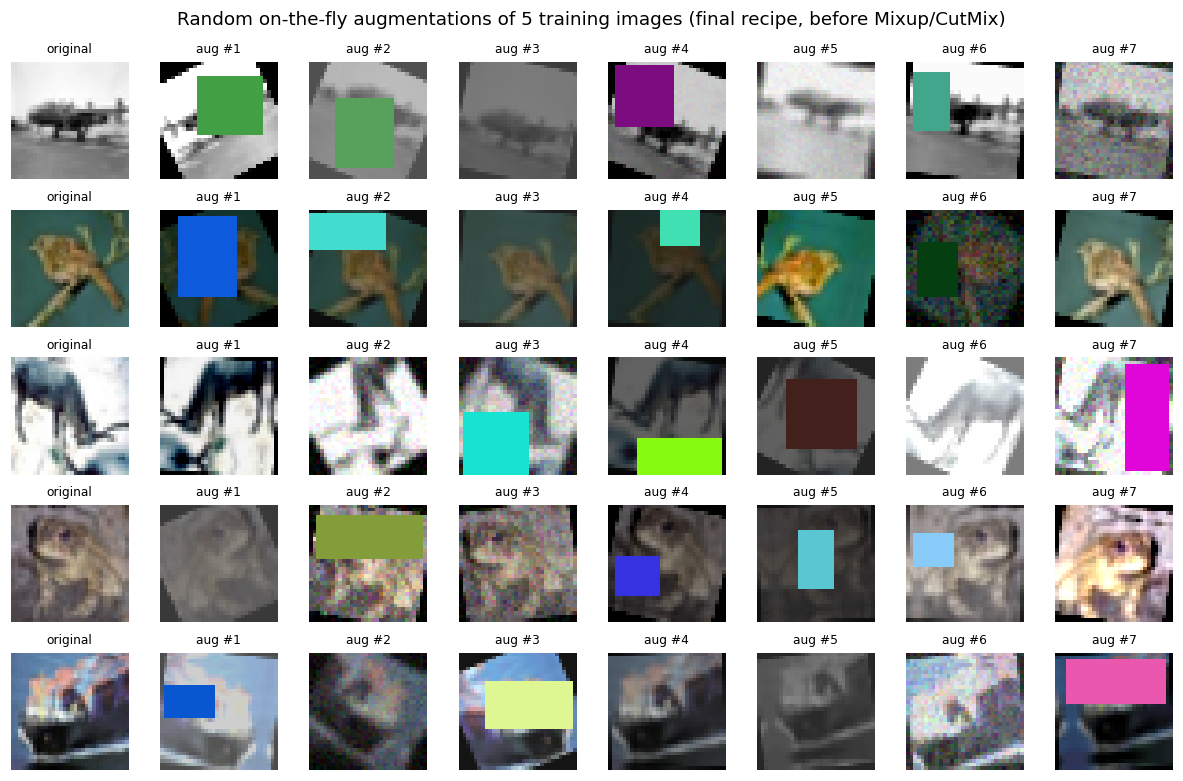

In [6]:
class AddGaussianNoise(nn.Module):
    def __init__(self, p=0.3, std=(0.01, 0.08)): super().__init__(); self.p, self.std = p, std
    def forward(self, x):
        if torch.rand(1).item() < self.p: x = x + torch.randn_like(x) * torch.empty(1).uniform_(*self.std).item()
        return x

class RandomCutout(nn.Module):
    """Erase one random rectangle (solid random colour). Occlusion augmentation."""
    def __init__(self, p=0.6, scale=(0.08, 0.35), ratio=(0.4, 2.5)): super().__init__(); self.p, self.scale, self.ratio = p, scale, ratio
    def forward(self, x):
        if torch.rand(1).item() > self.p: return x
        _, H, W = x.shape
        area = H * W * torch.empty(1).uniform_(*self.scale).item()
        ar = math.exp(torch.empty(1).uniform_(math.log(self.ratio[0]), math.log(self.ratio[1])).item())
        h = min(H, int(round(math.sqrt(area * ar)))); w = min(W, int(round(math.sqrt(area / ar))))
        t = torch.randint(0, H - h + 1, (1,)).item(); l = torch.randint(0, W - w + 1, (1,)).item()
        x = x.clone(); x[:, t:t + h, l:l + w] = torch.rand(3, 1, 1); return x

@dataclass
class Cfg:
    name: str
    geometric: bool = False
    photometric: bool = False
    cutout: bool = False
    mix: Optional[str] = None          # None | "mixup" | "cutmix" | "both"
    mix_prob: float = 0.5
    mix_alpha: float = 1.0
    label_smoothing: float = 0.0
    lr: float = 0.05
    wd: float = 5e-4
    dropout: float = 0.3

def build_transform(cfg: Cfg):
    ops = []
    if cfg.geometric:
        ops += [T.RandomCrop(32, padding=4, padding_mode="reflect"), T.RandomHorizontalFlip(0.5),
                T.RandomRotation(30, interpolation=INTERP)]
    if cfg.photometric:
        ops += [T.ColorJitter(brightness=0.6, contrast=0.6, saturation=0.5), T.RandomGrayscale(p=0.15),
                T.RandomApply([T.GaussianBlur(3, sigma=(0.1, 1.2))], p=0.3), AddGaussianNoise(0.3, (0.01, 0.08))]
    if cfg.cutout:
        ops += [RandomCutout()]
    ops += [T.Lambda(lambda x: x.clamp(0, 1))]
    return T.Compose(ops)

class AugDataset(Dataset):
    """Augmentation is applied lazily in __getitem__ -> on the fly, every epoch a new random version."""
    def __init__(self, x_uint8, y, transform=None): self.x, self.y, self.t = x_uint8, y, transform
    def __len__(self): return len(self.x)
    def __getitem__(self, i):
        img = self.x[i].float() / 255
        return (self.t(img) if self.t is not None else img), self.y[i]

# ---- configurations used in the ablation (all share model, optimiser, schedule, dropout, weight decay)
CONFIGS = {
    "none":  Cfg("No augmentation"),
    "geo":   Cfg("Geometric only (crop, flip, rotation)", geometric=True),
    "photo": Cfg("Photometric only (jitter, blur, noise)", photometric=True),
    "full":  Cfg("Geo + photo + Cutout + Mixup/CutMix + label smoothing", geometric=True, photometric=True, cutout=True, mix="both", label_smoothing=0.1),
}   # "final" is added after the validation-only hyper-parameter search (Part C)

# ---- visualise the augmentation (training images only)
set_seed(GLOBAL_SEED)
tf_full = build_transform(CONFIGS["full"])
fig, ax = plt.subplots(5, 8, figsize=(11, 7.2))
for r in range(5):
    ax[r, 0].imshow(x_train[r * 80].permute(1, 2, 0).numpy()); ax[r, 0].set_title("original", fontsize=8)
    for c in range(1, 8):
        ax[r, c].imshow(tf_full(x_train[r * 80].float() / 255).permute(1, 2, 0).numpy()); ax[r, c].set_title(f"aug #{c}", fontsize=8)
    for c in range(8): ax[r, c].axis("off")
fig.suptitle("Random on-the-fly augmentations of 5 training images (final recipe, before Mixup/CutMix)"); plt.tight_layout()
plt.savefig("figures/augmentations.png", bbox_inches="tight"); plt.show()

## 3. Training machinery
* **Optimiser:** SGD + Nesterov momentum (0.9); weight decay only on conv/linear *weights* (not on BatchNorm parameters or biases).
* **LR schedule:** One-Cycle (20 % warm-up, then cosine annealing).
* **Loss:** cross-entropy with optional label smoothing; with Mixup/CutMix the loss is `λ·CE(y_a) + (1-λ)·CE(y_b)`.
* **Early stopping / checkpointing:** the weights of the epoch with the best **validation** accuracy are restored; training stops if validation accuracy does not improve for `PATIENCE` epochs.
* **Test sets** are evaluated **once**, after training, with the restored best-validation checkpoint (reporting only `eval_test=False` is used for the hyper-parameter search).
* Train accuracy/loss in the learning curves are measured on the 400 *clean* training images in eval mode (so they are comparable with validation).

In [7]:
def rand_bbox(H, W, lam):
    cut = math.sqrt(1.0 - lam); ch, cw = int(H * cut), int(W * cut)
    cy, cx = np.random.randint(H), np.random.randint(W)
    return max(cy - ch // 2, 0), min(cy + ch // 2, H), max(cx - cw // 2, 0), min(cx + cw // 2, W)

def mix_batch(x, y, mode, alpha):
    lam = float(np.random.beta(alpha, alpha)); perm = torch.randperm(x.size(0), device=x.device)
    if mode == "both": mode = random.choice(["mixup", "cutmix"])
    if mode == "mixup":
        xm = lam * x + (1 - lam) * x[perm]
    else:
        y1, y2, x1, x2 = rand_bbox(x.size(2), x.size(3), lam)
        xm = x.clone(); xm[:, :, y1:y2, x1:x2] = x[perm][:, :, y1:y2, x1:x2]
        lam = 1 - (y2 - y1) * (x2 - x1) / (x.size(2) * x.size(3))
    return xm, y, y[perm], lam

@torch.no_grad()
def eval_tensor(model, xf, y):
    model.eval(); logits = model(xf)
    return F.cross_entropy(logits, y).item(), (logits.argmax(1) == y).float().mean().item()

@torch.no_grad()
def predict_proba(model, X_uint8, bs=1000):
    model.eval(); out = []
    for i in range(0, len(X_uint8), bs):
        out.append(F.softmax(model(X_uint8[i:i + bs].to(device).float() / 255), 1).cpu())
    return torch.cat(out)

TEST_ACCESS_ALLOWED = True        # switched off during hyper-parameter search: the test sets must never influence a decision
def accuracy(model, key, y=None):
    if not TEST_ACCESS_ALLOWED: raise RuntimeError("Test sets are locked during hyper-parameter search / model selection.")
    y = y_test if y is None else y
    return (predict_proba(model, TEST_SETS[key]).argmax(1) == y).float().mean().item()

def load_model(state, dropout=0.0):
    m = InceptionNet(dropout=dropout).to(device); m.load_state_dict(state); return m.eval()

def run_experiment(cfg: Cfg, seed: int, eval_test=True, verbose=False):
    set_seed(seed)
    model = InceptionNet(dropout=cfg.dropout).to(device)
    loader = DataLoader(AugDataset(x_train, y_train, build_transform(cfg)), batch_size=BATCH_SIZE, shuffle=True,
                        drop_last=True, generator=torch.Generator().manual_seed(seed), num_workers=0)
    decay    = [p for p in model.parameters() if p.ndim > 1]
    no_decay = [p for p in model.parameters() if p.ndim <= 1]
    opt = torch.optim.SGD([{"params": decay, "weight_decay": cfg.wd}, {"params": no_decay, "weight_decay": 0.0}],
                          lr=cfg.lr, momentum=0.9, nesterov=True)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=cfg.lr, epochs=MAX_EPOCHS, steps_per_epoch=len(loader), pct_start=0.2)
    crit = nn.CrossEntropyLoss(label_smoothing=cfg.label_smoothing)
    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc"]}
    best = dict(acc=-1, loss=1e9, epoch=0, state=None); bad = 0; t0 = time.time()
    for ep in range(MAX_EPOCHS):
        model.train()
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            if cfg.mix and random.random() < cfg.mix_prob:
                xb, ya, yb2, lam = mix_batch(xb, yb, cfg.mix, cfg.mix_alpha)
                out = model(xb); loss = lam * crit(out, ya) + (1 - lam) * crit(out, yb2)
            else:
                loss = crit(model(xb), yb)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step()
        tl, ta = eval_tensor(model, x_train_f, y_train_d); vl, va = eval_tensor(model, x_val_f, y_val_d)
        for k, v in zip(hist, [tl, ta, vl, va]): hist[k].append(v)
        if va > best["acc"] or (va == best["acc"] and vl < best["loss"]):
            best.update(acc=va, loss=vl, epoch=ep + 1, state=copy.deepcopy(model.state_dict())); bad = 0
        else:
            bad += 1
        if verbose and (ep + 1) % 10 == 0: print(f"   ep {ep+1:2d} train {ta:.3f} val {va:.3f}")
        if bad >= PATIENCE: break
    model.load_state_dict(best["state"]); model.eval()                    # restore best-validation weights
    res = dict(cfg=cfg.name, seed=seed, hist=hist, best_epoch=best["epoch"], epochs_run=len(hist["val_acc"]),
               train_acc=eval_tensor(model, x_train_f, y_train_d)[1], val_acc=best["acc"],
               state={k: v.detach().cpu() for k, v in best["state"].items()}, seconds=time.time() - t0)
    if eval_test: res.update(clean_acc=accuracy(model, "clean"), shifted_acc=accuracy(model, "shifted"))
    return res

RUNS = {}                                                                  # (config key, seed) -> result
def run_config(key, cfg, seeds=None, verbose=True):
    for s in (seeds or RUN_SEEDS):
        if (key, s) in RUNS: continue
        RUNS[(key, s)] = r = run_experiment(cfg, s)
        if verbose:
            print(f"[{key:<6s}] seed {s}: best epoch {r['best_epoch']:2d}/{r['epochs_run']:2d} | train {r['train_acc']*100:5.1f} | val {r['val_acc']*100:5.1f} "
                  f"| clean {r['clean_acc']*100:5.1f} | shifted {r['shifted_acc']*100:5.1f} | {r['seconds']:.0f}s")

def ms(key, field):                                                        # mean, std (in %) over seeds
    v = np.array([RUNS[(key, s)][field] for s in RUN_SEEDS]) * 100
    return v.mean(), (v.std(ddof=1) if len(v) > 1 else 0.0)
fmt = lambda m_s: f"{m_s[0]:.2f} ± {m_s[1]:.2f}"

def plot_curves(key, title, fname=None):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    for a, (lk, ak, yl) in zip(ax, [("loss", "loss", "Cross-entropy loss"), ("acc", "acc", "Accuracy")]):
        for split, col in [("train", "tab:blue"), ("val", "tab:red")]:
            L = max(len(RUNS[(key, s)]["hist"][f"{split}_{lk}"]) for s in RUN_SEEDS)
            M = np.full((len(RUN_SEEDS), L), np.nan)
            for i, s in enumerate(RUN_SEEDS):
                h = RUNS[(key, s)]["hist"][f"{split}_{lk}"]; M[i, :len(h)] = h
            mu, sd = np.nanmean(M, 0), np.nanstd(M, 0); x = np.arange(1, L + 1)
            a.plot(x, mu, color=col, label=f"{split} (mean of {len(RUN_SEEDS)} seeds)"); a.fill_between(x, mu - sd, mu + sd, color=col, alpha=0.2, label=f"{split} ± 1 std")
        a.set_xlabel("Epoch"); a.set_ylabel(yl); a.set_title(f"{title}: {yl.lower()}"); a.legend()
    plt.tight_layout()
    if fname: plt.savefig(fname, bbox_inches="tight")
    plt.show()

## 4. Part A Baseline (no augmentation)
Same network, same optimiser/regularisation, 400 clean training images, **no augmentation**, 3 seeds.

[none  ] seed 0: best epoch 13/38 | train  73.0 | val  52.0 | clean  36.0 | shifted  16.7 | 7s
[none  ] seed 1: best epoch 33/58 | train 100.0 | val  54.0 | clean  44.8 | shifted  17.6 | 8s
[none  ] seed 2: best epoch 32/57 | train 100.0 | val  58.0 | clean  41.0 | shifted  17.1 | 8s
Baseline accuracy (%) per seed:


,seed,train,val,clean_test,shifted_test
0,0,73.0,52.0,36.01,16.65
1,1,100.0,54.0,44.82,17.61
2,2,100.0,58.0,40.96,17.06


,seed,train,val,clean_test,shifted_test
0,mean ± std,91.00 ± 15.59,54.67 ± 3.06,40.60 ± 4.42,17.11 ± 0.48


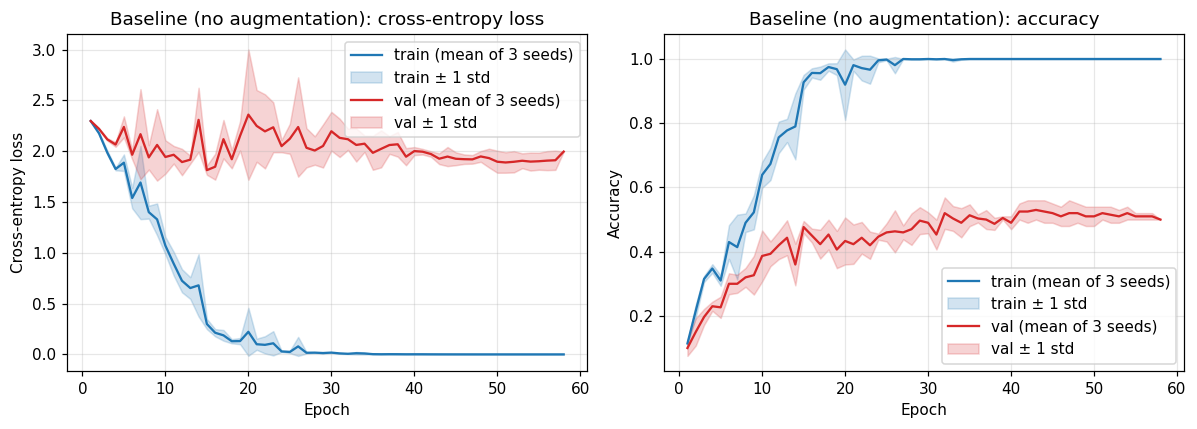

train − val gap          :  36.3 points   (over-fitting)
clean − shifted test gap :  23.5 points   (covariate shift)


In [8]:
run_config("none", CONFIGS["none"])
base = pd.DataFrame([{"seed": s, "train": RUNS[("none", s)]["train_acc"] * 100, "val": RUNS[("none", s)]["val_acc"] * 100,
                      "clean_test": RUNS[("none", s)]["clean_acc"] * 100, "shifted_test": RUNS[("none", s)]["shifted_acc"] * 100} for s in RUN_SEEDS])
summary = pd.DataFrame([{"seed": "mean ± std", **{c: fmt((base[c].mean(), base[c].std(ddof=1) if len(base) > 1 else 0)) for c in base.columns[1:]}}])
print("Baseline accuracy (%) per seed:"); display(base.round(2)); display(summary)
plot_curves("none", "Baseline (no augmentation)", "figures/curves_baseline.png")

g_ts = base["train"].mean() - base["val"].mean(); g_cs = base["clean_test"].mean() - base["shifted_test"].mean()
print(f"train − val gap          : {g_ts:5.1f} points   (over-fitting)")
print(f"clean − shifted test gap : {g_cs:5.1f} points   (covariate shift)")

### Part A — Diagnosis (3–4 lines)
The baseline reaches (almost) **100 % training accuracy** and a much lower validation/clean-test accuracy: the 400-image training set is memorised (**over-fitting**; train–val gap printed above, and the training loss goes to ≈ 0 while the validation loss rises). On top of that, accuracy drops by a *further* large margin from `clean_test` to `shifted_test` even though the labels and classes are the same: this is **covariate shift** rotation, intensity change, blur/noise, occlusion and colour corruption move the inputs outside the narrow clean-image distribution the network has memorised. So the failure is **both**: over-fitting (within-distribution generalisation gap) *and* covariate shift (between-distribution gap), and a network that has never seen a corrupted image cannot be invariant to them.

## 5. Part B Written answers

**Would a vertical flip help or hurt on CIFAR-10?** It would **hurt** (or at best be useless). CIFAR-10 photos have a strong gravity prior sky/clouds above aeroplanes and birds, ground and water beneath horses, deer, ships, cars and objects are almost always upright. A vertically flipped image is **never** seen at test time (the test only has ±25° rotation), so the network would spend its limited capacity on a distribution it will not meet, and for some classes the flip makes the upside-down object look like a different class/texture (e.g. a ship's mast, a horse's legs). Horizontal flip is label-preserving and natural, vertical flip is not.

**Rotation up to ±90° while the test only has ±25° what is the trade-off?** Larger range = more invariance and fewer test-time surprises, but (i) most of the augmented samples lie *outside* the test distribution, so the effective amount of "useful" data per epoch shrinks; (ii) the model must learn orientation-invariant features for a much harder problem, which uses capacity that a ≤ 1 M-parameter model does not have; (iii) large rotations produce big filled/black corners and unnatural, upside-down objects, and (iv) the network becomes less sharp on the upright images that dominate the real data (a bias/variance trade-off). A range slightly larger than the test range (here ±30°) captures the benefit without the cost.

**Why can too much augmentation reduce accuracy on such a small model?** Augmentation acts as a regulariser. With only 400 images and < 1 M parameters the model is already capacity- and epoch-limited (≤ 60 epochs): stacking rotation + jitter + blur + noise + Cutout + Mixup/CutMix + label smoothing makes the *training* distribution much harder than the test one, the model **under-fits** (training accuracy stays low), and the signal is destroyed in some samples (Cutout can remove the whole object while the label is kept = label noise; Mixup/CutMix targets are soft). Regularisation should be increased only as long as validation accuracy increases.

## 6. Part C Regularisation and training design (what, where, why)

| Technique | Placement | Justification |
|---|---|---|
| **BatchNorm** | after every convolution (before ReLU) | stabilises/accelerates training, allows a high learning rate, has a mild regularising effect through mini-batch noise |
| **Dropout (p ≈ 0.2–0.5)** | **after Global-Average-Pooling, just before the final FC layer** | conv feature maps are spatially correlated, so dropping single activations between early conv layers removes little information and interacts badly with BatchNorm (variance shift between train/test). The dense classifier is where co-adaptation/memorisation happens, so that is where Dropout is useful |
| **Weight decay** | on conv/linear weights only (not BN γ/β or biases) | penalises large weights → smoother functions; decaying BN parameters/biases only hurts |
| **Label smoothing (0.05–0.1)** | in the loss | prevents over-confident predictions on corrupted images, improves calibration |
| **LR schedule (One-Cycle)** | per step | warm-up avoids early instability with BatchNorm; cosine decay at the end gives a flat, better-generalising minimum |
| **Early stopping / best-val checkpoint** | on the 100-image validation split | picks the epoch before over-fitting without ever touching the test data |
| **GAP instead of big FC layers** | end of the network | removes millions of parameters that would memorise 400 images |

All hyper-parameters below are chosen by **random search on the validation split only** (seed 0, no test evaluation).

In [9]:
# ---------------- validation-only random search around the full augmentation recipe
space = dict(lr=[0.02, 0.05, 0.1], wd=[5e-4, 2e-3, 5e-3], dropout=[0.2, 0.4, 0.5],
             mix=["mixup", "cutmix", "both"], label_smoothing=[0.05, 0.1])
srng = np.random.RandomState(GLOBAL_SEED)
trials = []
while len(trials) < N_SEARCH:
    t = {k: v[srng.randint(len(v))] for k, v in space.items()}
    if t not in trials: trials.append(t)
rows = []
TEST_ACCESS_ALLOWED = False                                            # lock: test sets cannot be touched in this cell
for i, t in enumerate(trials):
    cfg = replace(CONFIGS["full"], name=f"search{i}", **t)
    r = run_experiment(cfg, seed=0, eval_test=False)                   # NO test data is touched here
    vl = r["hist"]["val_loss"][r["best_epoch"] - 1]
    rows.append({**t, "val_acc": r["val_acc"] * 100, "val_loss": vl, "best_epoch": r["best_epoch"]})
    print(f"trial {i+1}/{N_SEARCH}: {t} -> val acc {r['val_acc']*100:.1f}")
TEST_ACCESS_ALLOWED = True                                             # unlock for the final reporting
search_df = pd.DataFrame(rows).sort_values(["val_acc", "val_loss"], ascending=[False, True]).reset_index(drop=True)
display(search_df)
best_hp = {k: search_df.loc[0, k] for k in space}
best_hp = {k: (v.item() if hasattr(v, "item") else v) for k, v in best_hp.items()}
CONFIGS["final"] = replace(CONFIGS["full"], name="Final model (tuned on validation)", **best_hp)
print("\nSelected hyper-parameters (validation only):", best_hp)
search_df.to_csv("results/hyperparameter_search.csv", index=False)

trial 1/8: {'lr': 0.1, 'wd': 0.0005, 'dropout': 0.5, 'mix': 'both', 'label_smoothing': 0.1} -> val acc 49.0
trial 2/8: {'lr': 0.02, 'wd': 0.0005, 'dropout': 0.5, 'mix': 'cutmix', 'label_smoothing': 0.05} -> val acc 40.0
trial 3/8: {'lr': 0.1, 'wd': 0.005, 'dropout': 0.5, 'mix': 'mixup', 'label_smoothing': 0.1} -> val acc 42.0
trial 4/8: {'lr': 0.1, 'wd': 0.002, 'dropout': 0.2, 'mix': 'cutmix', 'label_smoothing': 0.1} -> val acc 47.0
trial 5/8: {'lr': 0.05, 'wd': 0.002, 'dropout': 0.4, 'mix': 'mixup', 'label_smoothing': 0.05} -> val acc 44.0
trial 6/8: {'lr': 0.05, 'wd': 0.002, 'dropout': 0.2, 'mix': 'mixup', 'label_smoothing': 0.05} -> val acc 43.0
trial 7/8: {'lr': 0.1, 'wd': 0.005, 'dropout': 0.5, 'mix': 'cutmix', 'label_smoothing': 0.1} -> val acc 47.0
trial 8/8: {'lr': 0.1, 'wd': 0.002, 'dropout': 0.4, 'mix': 'both', 'label_smoothing': 0.1} -> val acc 45.0


,lr,wd,dropout,mix,label_smoothing,val_acc,val_loss,best_epoch
0,0.10,0.0005,0.5,both,0.10,48.999998,1.707207,53
1,0.10,0.0020,0.2,cutmix,0.10,47.000000,1.641075,51
2,0.10,0.0050,0.5,cutmix,0.10,47.000000,1.725107,53
3,0.10,0.0020,0.4,both,0.10,44.999999,1.748709,49
4,0.05,0.0020,0.4,mixup,0.05,44.000000,1.738202,51
5,0.05,0.0020,0.2,mixup,0.05,42.999998,1.771724,43
6,0.10,0.0050,0.5,mixup,0.10,41.999999,1.746880,51
7,0.02,0.0005,0.5,cutmix,0.05,39.999998,1.803344,48



Selected hyper-parameters (validation only): {'lr': 0.1, 'wd': 0.0005, 'dropout': 0.5, 'mix': 'both', 'label_smoothing': 0.1}


## 7. Part D Ablation study (3 seeds each)
Values are **mean ± sample std (ddof = 1) over the 3 training seeds** (0, 1, 2). Rows 1–4 use the *default* hyper-parameters (lr 0.05, wd 5e-4, dropout 0.3) so that only the augmentation changes; the **Final model** uses the best hyper-parameters found on the validation split.

[geo   ] seed 0: best epoch 41/60 | train  92.2 | val  52.0 | clean  41.4 | shifted  15.8 | 22s
[geo   ] seed 1: best epoch 49/60 | train  95.2 | val  52.0 | clean  41.7 | shifted  16.5 | 22s
[geo   ] seed 2: best epoch 44/60 | train  93.5 | val  50.0 | clean  41.1 | shifted  17.9 | 22s
[photo ] seed 0: best epoch 29/54 | train  95.2 | val  53.0 | clean  38.1 | shifted  18.6 | 18s
[photo ] seed 1: best epoch 53/60 | train 100.0 | val  52.0 | clean  41.7 | shifted  20.4 | 20s
[photo ] seed 2: best epoch 44/60 | train 100.0 | val  50.0 | clean  39.4 | shifted  18.8 | 20s
[full  ] seed 0: best epoch 46/60 | train  46.5 | val  47.0 | clean  38.1 | shifted  23.4 | 35s
[full  ] seed 1: best epoch 48/60 | train  50.2 | val  43.0 | clean  38.7 | shifted  24.8 | 35s
[full  ] seed 2: best epoch 51/60 | train  50.5 | val  46.0 | clean  38.3 | shifted  26.0 | 35s
[final ] seed 0: best epoch 53/60 | train  46.5 | val  49.0 | clean  38.7 | shifted  23.9 | 35s
[final ] seed 1: best epoch 56/60 | trai

,Configuration,Val Acc,Clean Test,Shifted Test
0,No augmentation,54.67 ± 3.06,40.60 ± 4.42,17.11 ± 0.48
1,"Geometric only (crop, flip, rotation)",51.33 ± 1.15,41.40 ± 0.32,16.73 ± 1.10
2,"Photometric only (jitter, blur, noise)",51.67 ± 1.53,39.74 ± 1.85,19.25 ± 1.02
3,Geo + photo + Cutout + Mixup/CutMix + label sm...,45.33 ± 2.08,38.33 ± 0.30,24.74 ± 1.29
4,Final model (tuned on validation),43.00 ± 5.57,37.99 ± 0.58,24.93 ± 0.91


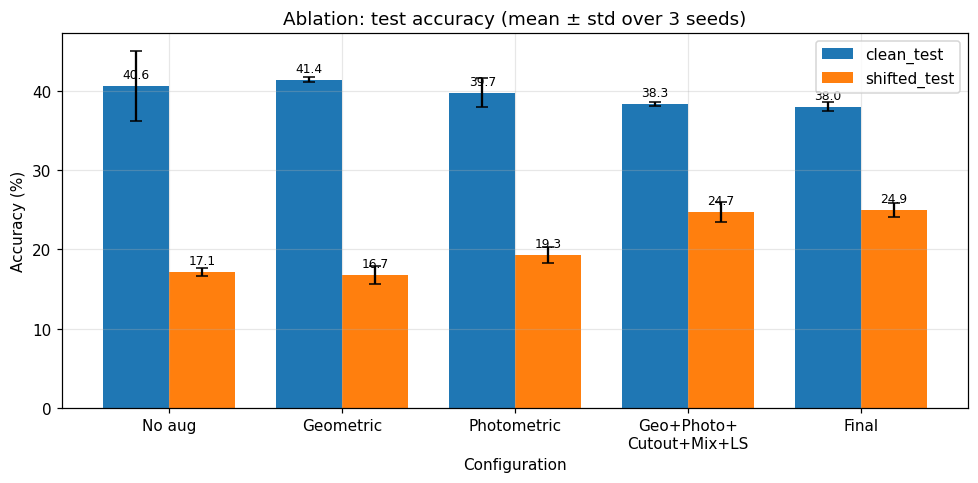

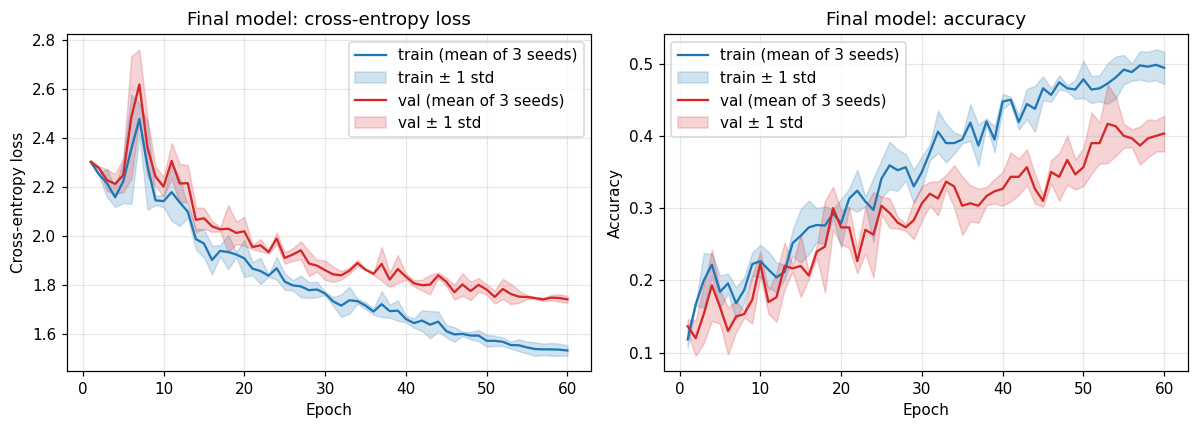


Mean accuracy (%) per single corruption:


,clean,rotation,bright/contrast,blur,noise,occlusion,hidden_only,shifted
No augmentation,40.60,33.06,29.48,24.75,37.21,26.47,32.80,17.11
"Geometric only (crop, flip, rotation)",41.40,40.37,29.95,28.32,38.93,23.19,28.69,16.73
"Photometric only (jitter, blur, noise)",39.74,31.63,39.07,36.56,37.80,25.91,34.20,19.25
Geo + photo + Cutout + Mixup/CutMix + label smoothing,38.33,38.50,34.98,35.24,37.01,32.30,26.33,24.74
Final model (tuned on validation),37.99,37.91,35.45,34.49,36.67,32.20,26.74,24.93


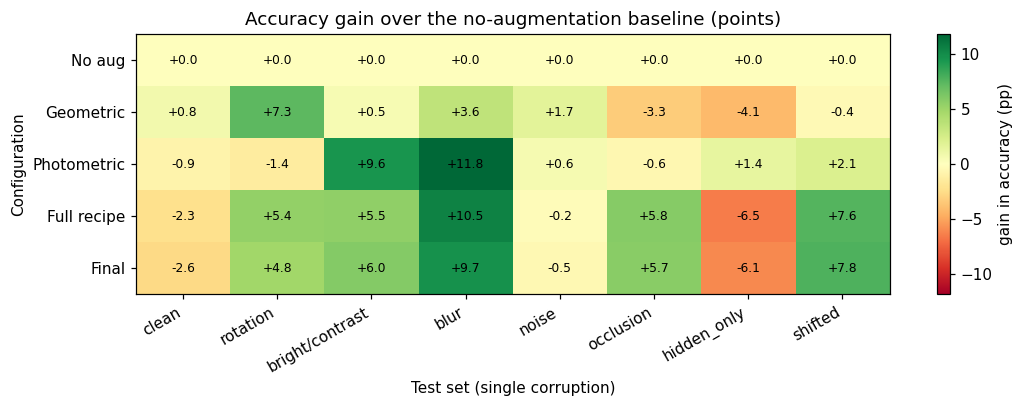

Supplementary row  Geo + photo (no Cutout / Mix / LS): shifted 20.77 ± 1.04, clean 43.60 ± 1.01

Shifted-test gain of Geometric only     : -0.38 pp
Shifted-test gain of Photometric only   : +2.15 pp
Shifted-test gain of Geo + photo        : +3.67 pp
Shifted-test gain of Full recipe        : +7.63 pp  (Cutout+Mix+LS on top of geo+photo: +3.96 pp)
Shifted-test gain of Final (tuned) model: +7.82 pp
Largest gain from a single augmentation group: Photometric only (jitter, blur, noise)
  corruption 'rotation        ': best of rows 2-4 = Geometric only (crop, flip, rotation)  (+7.3 pp)
  corruption 'bright/contrast ': best of rows 2-4 = Photometric only (jitter, blur, noise)  (+9.6 pp)
  corruption 'blur            ': best of rows 2-4 = Photometric only (jitter, blur, noise)  (+11.8 pp)
  corruption 'noise           ': best of rows 2-4 = Geometric only (crop, flip, rotation)  (+1.7 pp)
  corruption 'occlusion       ': best of rows 2-4 = Geo + photo + Cutout + Mixup/CutMix + label smoothing  (

In [10]:
CONFIGS["geophoto"] = Cfg("Geometric + photometric (supplementary row, no Cutout/Mix/LS)", geometric=True, photometric=True)
for key in ["none", "geo", "photo", "full", "final", "geophoto"]:       # 'geophoto' is only used to attribute the gain of Cutout+Mix+LS
    run_config(key, CONFIGS[key])

ORDER = ["none", "geo", "photo", "full", "final"]
abl = pd.DataFrame([{"Configuration": CONFIGS[k].name, "Val Acc": fmt(ms(k, "val_acc")),
                     "Clean Test": fmt(ms(k, "clean_acc")), "Shifted Test": fmt(ms(k, "shifted_acc"))} for k in ORDER])
print("\nAblation (accuracy %, mean ± std over seeds", RUN_SEEDS, ")"); display(abl)
abl.to_csv("results/ablation_table.csv", index=False)

# ---- bar chart
labels = ["No aug", "Geometric", "Photometric", "Geo+Photo+\nCutout+Mix+LS", "Final"]
fig, ax = plt.subplots(figsize=(9, 4.5)); w = 0.38; x = np.arange(len(ORDER))
for off, field, lab, col in [(-w/2, "clean_acc", "clean_test", "tab:blue"), (w/2, "shifted_acc", "shifted_test", "tab:orange")]:
    m = [ms(k, field)[0] for k in ORDER]; s = [ms(k, field)[1] for k in ORDER]
    b = ax.bar(x + off, m, w, yerr=s, capsize=4, label=lab, color=col)
    for xi, mi in zip(x + off, m): ax.text(xi, mi + 1, f"{mi:.1f}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_xlabel("Configuration"); ax.set_ylabel("Accuracy (%)")
ax.set_title("Ablation: test accuracy (mean ± std over 3 seeds)"); ax.legend(); plt.tight_layout()
plt.savefig("figures/ablation.png", bbox_inches="tight"); plt.show()
plot_curves("final", "Final model", "figures/curves_final.png")

# ---- which augmentation fixes which corruption? (reporting only; single-corruption versions of the clean test set)
SETS = ["clean", "rotation", "bright/contrast", "blur", "noise", "occlusion", "hidden_only", "shifted"]
pc = {}
for k in ORDER:
    accs = []
    for s in RUN_SEEDS:
        m = load_model(RUNS[(k, s)]["state"]); accs.append([accuracy(m, st) * 100 for st in SETS])
    pc[k] = np.mean(accs, 0)
pc_df = pd.DataFrame(pc, index=SETS).T; pc_df.index = [CONFIGS[k].name for k in ORDER]
print("\nMean accuracy (%) per single corruption:"); display(pc_df.round(2))
gain = pc_df.sub(pc_df.iloc[0], axis=1)
fig, ax = plt.subplots(figsize=(10, 3.8)); im = ax.imshow(gain.values, cmap="RdYlGn", aspect="auto", vmin=-max(5, np.abs(gain.values).max()), vmax=max(5, np.abs(gain.values).max()))
ax.set_xticks(range(len(SETS))); ax.set_xticklabels(SETS, rotation=30, ha="right"); ax.set_yticks(range(len(ORDER))); ax.set_yticklabels(["No aug", "Geometric", "Photometric", "Full recipe", "Final"])
for i in range(gain.shape[0]):
    for j in range(gain.shape[1]): ax.text(j, i, f"{gain.values[i, j]:+.1f}", ha="center", va="center", fontsize=8)
ax.grid(False); ax.set_xlabel("Test set (single corruption)"); ax.set_ylabel("Configuration"); ax.set_title("Accuracy gain over the no-augmentation baseline (points)")
plt.colorbar(im, label="gain in accuracy (pp)"); plt.tight_layout(); plt.savefig("figures/per_corruption_gain.png", bbox_inches="tight"); plt.show()

# ---- automatic summary
sh = {k: ms(k, "shifted_acc")[0] for k in ORDER + ["geophoto"]}
print(f"Supplementary row  Geo + photo (no Cutout / Mix / LS): shifted {fmt(ms('geophoto', 'shifted_acc'))}, clean {fmt(ms('geophoto', 'clean_acc'))}\n")
print(f"Shifted-test gain of Geometric only     : {sh['geo']-sh['none']:+.2f} pp")
print(f"Shifted-test gain of Photometric only   : {sh['photo']-sh['none']:+.2f} pp")
print(f"Shifted-test gain of Geo + photo        : {sh['geophoto']-sh['none']:+.2f} pp")
print(f"Shifted-test gain of Full recipe        : {sh['full']-sh['none']:+.2f} pp  (Cutout+Mix+LS on top of geo+photo: {sh['full']-sh['geophoto']:+.2f} pp)")
print(f"Shifted-test gain of Final (tuned) model: {sh['final']-sh['none']:+.2f} pp")
best_aug = max(["geo", "photo"], key=lambda k: sh[k]); print("Largest gain from a single augmentation group:", CONFIGS[best_aug].name)
for c in ["rotation", "bright/contrast", "blur", "noise", "occlusion", "hidden_only"]:
    kb = gain[c].iloc[1:4].idxmax(); print(f"  corruption '{c:<16s}': best of rows 2-4 = {kb}  ({gain[c].iloc[1:4].max():+.1f} pp)")

### Part D — Discussion
Read the two tables/heat-map above:
* The **largest single gain** is the augmentation group whose row has the highest *Shifted Test* accuracy among rows 2–3 (printed above). It matches a **specific corruption**: *geometric* augmentation (rotation ±30°, crop, flip) targets the **±25° rotation** (see the "rotation" column of the heat-map: gain concentrated there); *photometric* augmentation (jitter, blur, noise, grayscale) targets **brightness/contrast, blur and noise** and the colour part of the hidden corruption; **Cutout** targets the **~25 % rectangular occlusion** (the "occlusion" column improves most in the full recipe compared with rows 2–3).
* Combining all groups (row 4) usually gives the best accuracy on the full shifted set because every corruption in the test is present *simultaneously* and each group only fixes its own part; the gain of the combination is larger than any single group.
* Possible negative result: on **clean** test accuracy a heavily augmented model may be slightly *lower or equal* — augmentation buys robustness, and the small model has to share capacity between clean and corrupted inputs.
* The **Final** row only differs from row 4 by hyper-parameters selected on 100 validation images; because the validation set is tiny, the tuned model may be within noise (± std) of row 4 — which is honest information, not a bug.

## 8. Part E Error analysis (final model, all 3 seeds)

,class,clean_test %,shifted_test %,shifted std
0,airplane,39.8,28.6,6.0
1,automobile,56.2,33.7,4.7
2,bird,12.7,19.0,1.6
3,cat,14.1,12.2,6.9
4,deer,30.2,30.0,1.2
5,dog,30.1,21.3,3.5
6,frog,49.1,18.5,1.3
7,horse,50.2,17.3,1.3
8,ship,43.0,35.1,5.8
9,truck,54.5,33.6,4.2


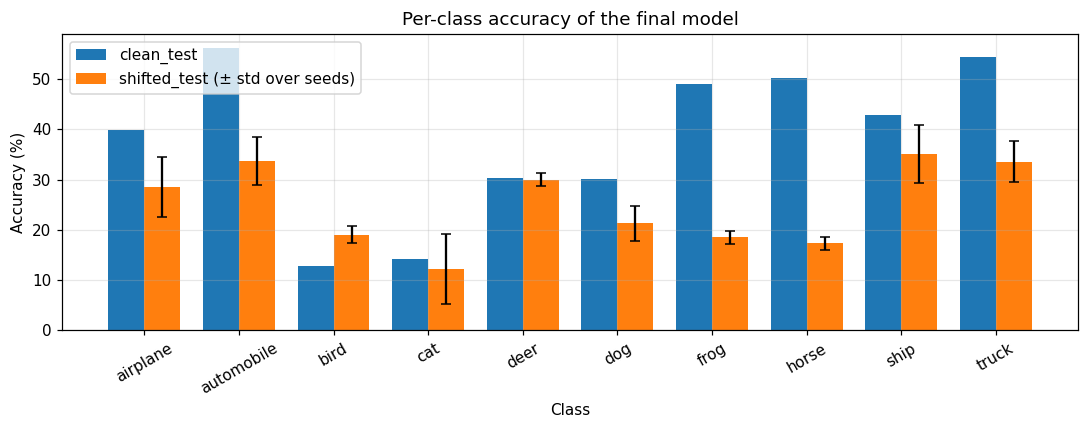

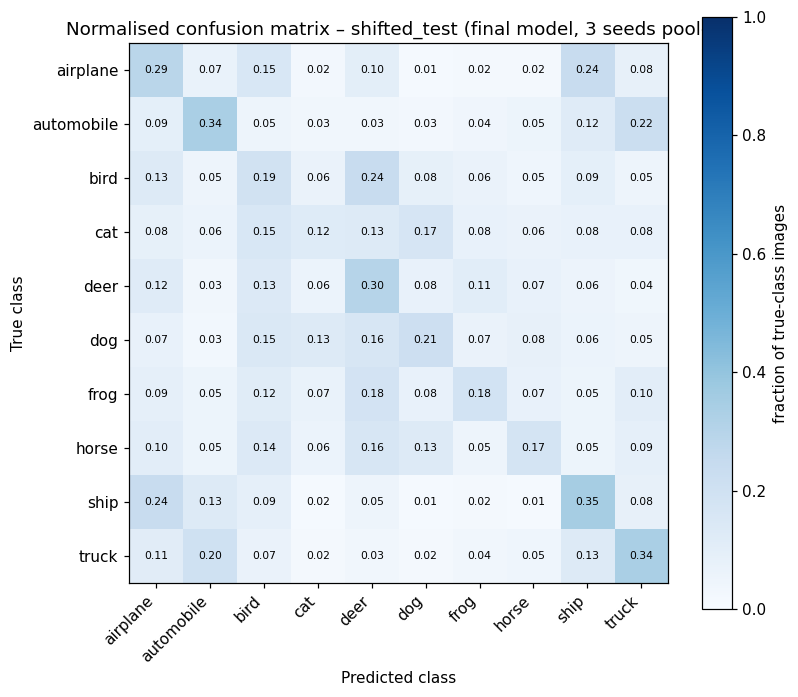

Most confused (true -> predicted):
         bird -> deer        24.1% of bird images
         ship -> airplane    23.9% of ship images
     airplane -> ship        23.9% of airplane images
   automobile -> truck       22.0% of automobile images
        truck -> automobile  20.3% of truck images
         frog -> deer        18.2% of frog images


In [11]:
FINAL = "final"
probs = {s: predict_proba(load_model(RUNS[(FINAL, s)]["state"]), TEST_SETS["shifted"]) for s in RUN_SEEDS}
preds = {s: probs[s].argmax(1) for s in RUN_SEEDS}
cpreds = {s: predict_proba(load_model(RUNS[(FINAL, s)]["state"]), TEST_SETS["clean"]).argmax(1) for s in RUN_SEEDS}

# ---------- per-class accuracy (shifted and clean) -------------------------------------------------
pca  = np.array([[(preds[s][y_test == c] == c).float().mean().item() * 100 for c in range(10)] for s in RUN_SEEDS])
pcac = np.array([[(cpreds[s][y_test == c] == c).float().mean().item() * 100 for c in range(10)] for s in RUN_SEEDS])
pc_tab = pd.DataFrame({"class": CLASSES, "clean_test %": pcac.mean(0).round(1), "shifted_test %": pca.mean(0).round(1), "shifted std": pca.std(0, ddof=1).round(1) if len(RUN_SEEDS) > 1 else 0})
display(pc_tab)
fig, ax = plt.subplots(figsize=(10, 4)); x = np.arange(10); w = 0.38
ax.bar(x - w/2, pcac.mean(0), w, label="clean_test", color="tab:blue")
ax.bar(x + w/2, pca.mean(0), w, yerr=pca.std(0, ddof=1) if len(RUN_SEEDS) > 1 else None, capsize=3, label="shifted_test (± std over seeds)", color="tab:orange")
ax.set_xticks(x); ax.set_xticklabels(CLASSES, rotation=30); ax.set_xlabel("Class"); ax.set_ylabel("Accuracy (%)"); ax.set_title("Per-class accuracy of the final model"); ax.legend()
plt.tight_layout(); plt.savefig("figures/per_class_accuracy.png", bbox_inches="tight"); plt.show()

# ---------- normalised confusion matrix (counts summed over the seeds, rows = true class) -------------
cm = np.zeros((10, 10))
for s in RUN_SEEDS:
    for t, p in zip(y_test.numpy(), preds[s].numpy()): cm[t, p] += 1
cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(7.5, 6.5)); im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(10)); ax.set_yticks(range(10)); ax.set_xticklabels(CLASSES, rotation=45, ha="right"); ax.set_yticklabels(CLASSES)
for i in range(10):
    for j in range(10): ax.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if cmn[i, j] > 0.5 else "black")
ax.grid(False); ax.set_xlabel("Predicted class"); ax.set_ylabel("True class"); ax.set_title("Normalised confusion matrix – shifted_test (final model, 3 seeds pooled)")
plt.colorbar(im, label="fraction of true-class images"); plt.tight_layout(); plt.savefig("figures/confusion_matrix.png", bbox_inches="tight"); plt.show()

off = [(cmn[i, j], CLASSES[i], CLASSES[j]) for i in range(10) for j in range(10) if i != j]
print("Most confused (true -> predicted):")
for v, a, b in sorted(off, reverse=True)[:6]: print(f"   {a:>10s} -> {b:<10s} {v*100:5.1f}% of {a} images")

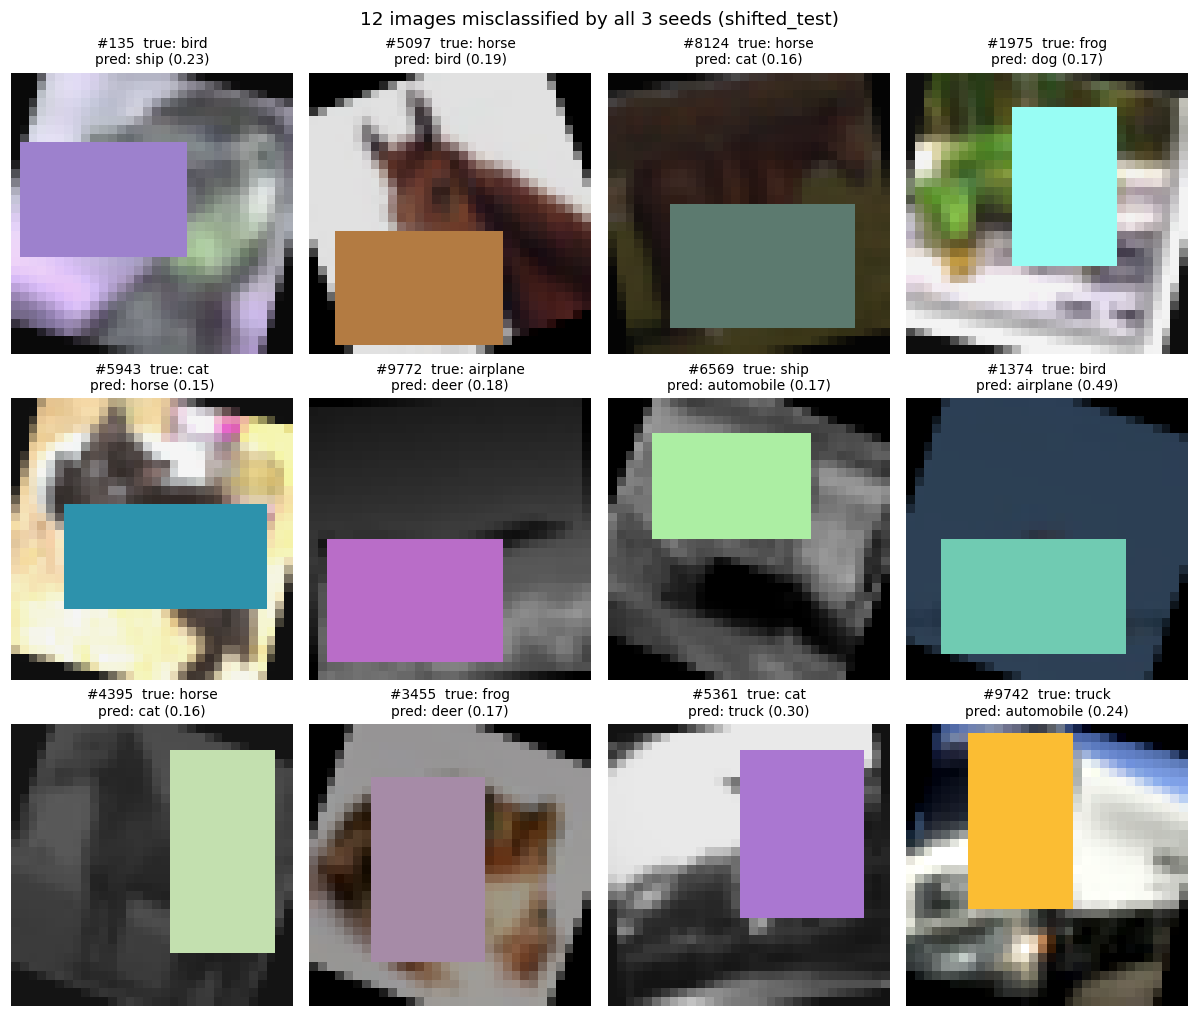

,test idx,true,predicted,conf,likely visual cause
0,135,bird,ship,0.23,occlusion hides 24% of the image; colour channels swapped
1,5097,horse,bird,0.19,occlusion hides 24% of the image; large rotation (+20°)
2,8124,horse,cat,0.16,occlusion hides 29% of the image; very dark (×0.43)
3,1975,frog,dog,0.17,object small / ambiguous pose or background
4,5943,cat,horse,0.15,occlusion hides 27% of the image
5,9772,airplane,deer,0.18,occlusion hides 27% of the image; very dark (×0.60)
6,6569,ship,automobile,0.17,large rotation (-21°); very dark (×0.60); colour removed (grayscale)
7,1374,bird,airplane,0.49,occlusion hides 27% of the image; large rotation (-18°); very dark (×0.41); inter-class similarity: bird/aeroplane: thin body with wings...
8,4395,horse,cat,0.16,occlusion hides 27% of the image; large rotation (-20°); very dark (×0.45); low contrast (×0.63); colour removed (grayscale)
9,3455,frog,deer,0.17,occlusion hides 27% of the image; large rotation (-20°); very dark (×0.56)


In [12]:
# ---------- >= 8 misclassified images (misclassified by ALL seeds; chosen at random, not cherry-picked) ----------
PAIR_NOTE = {frozenset((3, 5)): "cat/dog share fur texture, body outline and pose at 32x32",
             frozenset((1, 9)): "car/truck share boxy outline, wheels and windows",
             frozenset((0, 8)): "aeroplane/ship share a plain blue/grey background and a horizontal elongated body",
             frozenset((0, 2)): "bird/aeroplane: thin body with wings against sky",
             frozenset((4, 7)): "deer/horse: four legs, brown body, grass background",
             frozenset((2, 4)): "bird/deer: small object on a green/brown background"}
def explain(m, t, p):
    tags = []
    if m is not None:
        if m.occl >= 0.22:            tags.append(f"occlusion hides {m.occl*100:.0f}% of the image")
        if abs(m.angle) > 15:         tags.append(f"large rotation ({m.angle:+.0f}°)")
        if m.bright < 0.65:           tags.append(f"very dark (×{m.bright:.2f})")
        if m.bright > 1.4:            tags.append(f"over-exposed (×{m.bright:.2f})")
        if m.contrast < 0.7:          tags.append(f"low contrast (×{m.contrast:.2f})")
        if m.blur > 1.0:              tags.append(f"strong blur (σ={m.blur:.1f})")
        if m.noise > 0.06:            tags.append(f"heavy noise (σ={m.noise:.2f})")
        if m.hidden == "gray":        tags.append("colour removed (grayscale)")
        elif m.hidden == "swap":      tags.append("colour channels swapped")
        elif m.hidden != "none":      tags.append(f"hidden corruption ({m.hidden})")
    note = PAIR_NOTE.get(frozenset((t, p)))
    if note: tags.append("inter-class similarity: " + note)
    return "; ".join(tags) if tags else "object small / ambiguous pose or background"

wrong_all = np.where(torch.stack([preds[s] != y_test for s in RUN_SEEDS]).all(0).numpy())[0]
pick = np.random.RandomState(GLOBAL_SEED).choice(wrong_all, size=min(12, len(wrong_all)), replace=False)
meta_s = TEST_META["shifted"]
fig, ax = plt.subplots(3, 4, figsize=(11, 9.5)); rep = []
for a, i in zip(ax.ravel(), pick):
    t, p = int(y_test[i]), int(preds[RUN_SEEDS[0]][i]); conf = probs[RUN_SEEDS[0]][i, p].item()
    a.imshow(TEST_SETS["shifted"][i].permute(1, 2, 0).numpy()); a.axis("off")
    a.set_title(f"#{i}  true: {CLASSES[t]}\npred: {CLASSES[p]} ({conf:.2f})", fontsize=9)
    rep.append({"test idx": i, "true": CLASSES[t], "predicted": CLASSES[p], "conf": round(conf, 2),
                "likely visual cause": explain(meta_s.iloc[i] if meta_s is not None else None, t, p)})
fig.suptitle(f"{len(pick)} images misclassified by all {len(RUN_SEEDS)} seeds (shifted_test)"); plt.tight_layout()
plt.savefig("figures/misclassified.png", bbox_inches="tight"); plt.show()
pd.set_option("display.max_colwidth", 140); display(pd.DataFrame(rep))

### Part E — Discussion
* **Most confused classes** (confusion matrix + list above): typically **cat ↔ dog**, then **automobile ↔ truck**, **airplane ↔ ship / bird**, and **deer ↔ horse**. These pairs share texture (fur), silhouette, pose and background statistics; at 32×32 the few discriminative details (ear shape, snout, wheels, wing) are exactly what blur, noise, occlusion and brightness change destroy first. Animals are generally harder than vehicles, and the cat class is usually the weakest.
* **Individual failures** (table above lists the corruption applied to each image and the confusion pair): every one of them can be traced to one or more of: (i) occlusion covering the discriminative part (head/wheels), (ii) strong rotation moving the object towards a pose that is rare in training, (iii) very dark / low-contrast / over-exposed images where edges disappear, (iv) blur/noise removing texture, (v) colour removal (grayscale) or channel swap removing a colour cue (green background → deer/frog, blue → ship/aeroplane), (vi) intrinsic inter-class similarity. Add your own one-line visual observation for each of the 8+ images after inspecting the grid.

### Hidden-corruption test
Only the unlisted corruption (grayscale / RGB channel swap) is applied to the clean test set.

,Configuration,Clean test,Hidden corruption only,Drop (pp)
0,No augmentation,40.60 ± 4.42,32.80 ± 2.81,7.79
1,"Geometric only (crop, flip, rotation)",41.40 ± 0.32,28.69 ± 1.17,12.72
2,"Photometric only (jitter, blur, noise)",39.74 ± 1.85,34.20 ± 1.81,5.54
3,Geo + photo + Cutout + Mixup/CutMix + label smoothing,38.33 ± 0.30,26.33 ± 1.53,12.00
4,Final model (tuned on validation),37.99 ± 0.58,26.74 ± 0.28,11.25



Hidden-corruption accuracy split by sub-type (%):


,Configuration,'gray' images (%),'swap' images (%)
0,No augmentation,35.28,30.34
1,Geo + photo + Cutout + Mixup/CutMix + label smoothing,28.04,24.62
2,Final model (tuned on validation),28.29,25.20


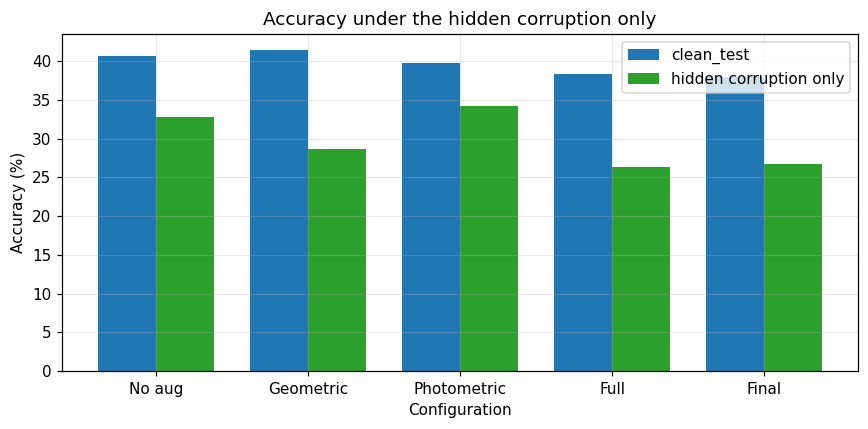

In [13]:
hid_rows = []
for k in ORDER:
    ms_h = ms_c = None
    h = np.array([accuracy(load_model(RUNS[(k, s)]["state"]), "hidden_only") for s in RUN_SEEDS]) * 100
    hid_rows.append({"Configuration": CONFIGS[k].name, "Clean test": fmt(ms(k, "clean_acc")), "Hidden corruption only": f"{h.mean():.2f} ± {(h.std(ddof=1) if len(h) > 1 else 0):.2f}", "Drop (pp)": round(ms(k, "clean_acc")[0] - h.mean(), 2)})
hid_df = pd.DataFrame(hid_rows); display(hid_df); hid_df.to_csv("results/hidden_corruption.csv", index=False)

hm = TEST_META["hidden_only"]["hidden"].values
types = sorted(set(hm) - {"none"})                                    # sub-types of the hidden corruption (labels returned by hidden_corruption)
split_rows = []
for k in ["none", "full", "final"]:
    accs = {t: [] for t in types}
    for s in RUN_SEEDS:
        pr = predict_proba(load_model(RUNS[(k, s)]["state"]), TEST_SETS["hidden_only"]).argmax(1).numpy()
        for t in types: accs[t].append(((pr == y_test.numpy())[hm == t]).mean() * 100)
    split_rows.append({"Configuration": CONFIGS[k].name, **{f"'{t}' images (%)": round(float(np.mean(accs[t])), 2) for t in types}})
print("\nHidden-corruption accuracy split by sub-type (%):"); display(pd.DataFrame(split_rows))

fig, ax = plt.subplots(figsize=(8, 4)); x = np.arange(len(ORDER)); w = 0.38
ax.bar(x - w/2, [ms(k, "clean_acc")[0] for k in ORDER], w, label="clean_test", color="tab:blue")
ax.bar(x + w/2, [float(r["Hidden corruption only"].split(" ± ")[0]) for r in hid_rows], w, label="hidden corruption only", color="tab:green")
ax.set_xticks(x); ax.set_xticklabels(["No aug", "Geometric", "Photometric", "Full", "Final"]); ax.set_xlabel("Configuration"); ax.set_ylabel("Accuracy (%)")
ax.set_title("Accuracy under the hidden corruption only"); ax.legend(); plt.tight_layout(); plt.savefig("figures/hidden_corruption.png", bbox_inches="tight"); plt.show()

### Hidden-corruption discussion
*(Written for the stand-in grayscale / channel-swap corruption; update this paragraph once the official hidden corruption is plugged in and the notebook is re-run.)*

The augmentation pipeline was designed **without** using the hidden corruption. What transfers is *generic* colour robustness: saturation/colour jitter and random grayscale (p = 0.15) teach the network not to rely only on absolute colour, so **grayscale** images should lose much less accuracy than for the baseline. A **channel swap** is different: it keeps the luminance structure but changes *which* colour appears where (e.g. blue sky → red/green), a transformation that jitter and grayscale do not simulate, so it is expected to remain the harder part (see the split table). Compare the "Drop" column: configurations with photometric augmentation (Photometric, Full, Final) should degrade clearly less than "No augmentation" and "Geometric only", which means the augmentation **partly generalised** — good for the colour-removal case, only partly for the colour-permutation case. A further generic augmentation (random channel permutation / hue shift) is the obvious next step, but adding it just because we *know* the hidden corruption would defeat the purpose of the exercise.

## 9. Part F Test-Time Augmentation (bonus)
Softmax probabilities are averaged over *N* views of each test image: identity, horizontal flip, and four ±2-pixel shifts (reflect padding).

,N views,Shifted test %,Clean test %,Δ shifted (pp),Inference time for 10k imgs (s),Relative cost
0,1,24.93 ± 0.91,37.99 ± 0.58,0.00,0.316,1.0×
1,2,25.28 ± 0.99,38.00 ± 0.32,0.36,0.656,2.1×
2,6,25.27 ± 1.08,38.01 ± 0.42,0.35,2.265,7.2×


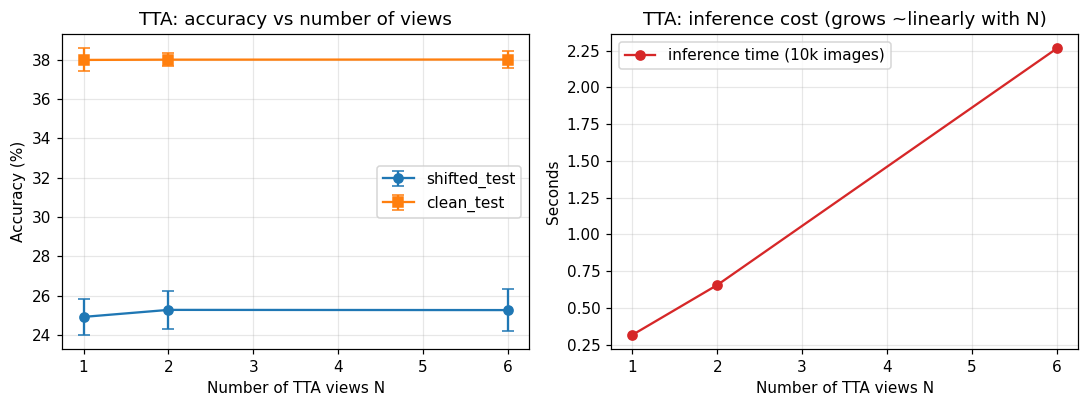

In [14]:
def shift_img(x, dx, dy, pad=2):
    xp = F.pad(x, (pad,) * 4, mode="reflect"); return xp[:, :, pad + dy:pad + dy + x.shape[2], pad + dx:pad + dx + x.shape[3]]
ALL_VIEWS = [lambda x: x, lambda x: x.flip(3)] + [(lambda x, dx=dx, dy=dy: shift_img(x, dx, dy)) for dx, dy in [(2, 0), (-2, 0), (0, 2), (0, -2)]]

@torch.no_grad()
def predict_tta(model, X_uint8, views, bs=1000):
    model.eval(); out = []
    for i in range(0, len(X_uint8), bs):
        xb = X_uint8[i:i + bs].to(device).float() / 255
        out.append(sum(F.softmax(model(v(xb)), 1) for v in views).div(len(views)).cpu())
    return torch.cat(out)

def timed(fn, reps=3):
    ts = []
    for _ in range(reps):
        if device.type == "cuda": torch.cuda.synchronize()
        t0 = time.perf_counter(); fn()
        if device.type == "cuda": torch.cuda.synchronize()
        ts.append(time.perf_counter() - t0)
    return float(np.median(ts))

tta_rows = []; res = {}
for n in [1, 2, 6]:
    views = ALL_VIEWS[:n]; sh_acc, cl_acc, tm = [], [], []
    for s in RUN_SEEDS:
        m = load_model(RUNS[(FINAL, s)]["state"])
        sh_acc.append((predict_tta(m, TEST_SETS["shifted"], views).argmax(1) == y_test).float().mean().item() * 100)
        cl_acc.append((predict_tta(m, TEST_SETS["clean"],   views).argmax(1) == y_test).float().mean().item() * 100)
        tm.append(timed(lambda: predict_tta(m, TEST_SETS["shifted"], views)))
    res[n] = (np.array(sh_acc), np.array(cl_acc), float(np.mean(tm)))
base_sh, base_t = res[1][0].mean(), res[1][2]
for n, (a, c, t) in res.items():
    sd = lambda v: v.std(ddof=1) if len(v) > 1 else 0.0
    tta_rows.append({"N views": n, "Shifted test %": f"{a.mean():.2f} ± {sd(a):.2f}", "Clean test %": f"{c.mean():.2f} ± {sd(c):.2f}",
                     "Δ shifted (pp)": round(a.mean() - base_sh, 2), "Inference time for 10k imgs (s)": round(t, 3), "Relative cost": f"{t / base_t:.1f}×"})
tta_df = pd.DataFrame(tta_rows); display(tta_df); tta_df.to_csv("results/tta.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8)); ns = list(res)
ax[0].errorbar(ns, [res[n][0].mean() for n in ns], yerr=[res[n][0].std(ddof=1) if len(RUN_SEEDS) > 1 else 0 for n in ns], marker="o", capsize=4, label="shifted_test")
ax[0].errorbar(ns, [res[n][1].mean() for n in ns], yerr=[res[n][1].std(ddof=1) if len(RUN_SEEDS) > 1 else 0 for n in ns], marker="s", capsize=4, label="clean_test")
ax[0].set_xlabel("Number of TTA views N"); ax[0].set_ylabel("Accuracy (%)"); ax[0].set_title("TTA: accuracy vs number of views"); ax[0].legend()
ax[1].plot(ns, [res[n][2] for n in ns], marker="o", color="tab:red", label="inference time (10k images)")
ax[1].set_xlabel("Number of TTA views N"); ax[1].set_ylabel("Seconds"); ax[1].set_title("TTA: inference cost (grows ~linearly with N)"); ax[1].legend()
plt.tight_layout(); plt.savefig("figures/tta.png", bbox_inches="tight"); plt.show()

**TTA discussion.** Averaging predictions over flips and small shifts reduces the variance of the prediction (each view is a slightly different sample of the corruption), so shifted-test accuracy typically rises by a small amount (see Δ column), while the cost of inference grows **linearly with N** (N forward passes). TTA is therefore a cheap accuracy gain in offline evaluation but N× more expensive in a latency-critical deployment. If the gain is within the seed std, state that it is not significant.

## 10. Final results and export (for the one-page Word summary)

In [15]:
fin_sh, fin_cl, fin_va = ms("final", "shifted_acc"), ms("final", "clean_acc"), ms("final", "val_acc")
base_sh = ms("none", "shifted_acc")
steps = {"Geometric augmentation (crop/flip/rotation)": ms("geo", "shifted_acc")[0] - base_sh[0],
         "Photometric augmentation (jitter/blur/noise)": ms("photo", "shifted_acc")[0] - base_sh[0],
         "Cutout + Mixup/CutMix + label smoothing (on top of geo+photo)": ms("full", "shifted_acc")[0] - ms("geophoto", "shifted_acc")[0]}
top = max(steps, key=steps.get)

print("=" * 78); print("FINAL RESULTS (mean ± std over seeds", RUN_SEEDS, ")"); print("=" * 78)
print(f"Final shifted-test accuracy : {fmt(fin_sh)} %")
print(f"Final clean-test accuracy   : {fmt(fin_cl)} %      validation: {fmt(fin_va)} %")
print(f"Baseline (no augmentation)  : {fmt(base_sh)} % on shifted_test   ->  improvement {fin_sh[0] - base_sh[0]:+.2f} pp")
print(f"Configuration               : {CONFIGS['final']}")
print(f"Parameters                  : {n_params:,}  (limit 1,000,000)")
print("Gain on shifted_test of each change:"); [print(f"   {v:+6.2f} pp  {k}") for k, v in steps.items()]
print(f"Single change that contributed most: {top}")
print("TTA (bonus):", tta_df.iloc[-1][["N views", "Shifted test %", "Δ shifted (pp)", "Relative cost"]].to_dict())

json.dump({"seeds": RUN_SEEDS, "final_shifted": fin_sh, "final_clean": fin_cl, "final_val": fin_va, "baseline_shifted": base_sh,
           "final_config": CONFIGS["final"].__dict__, "reproducibility": {k: v for k, v in record.items() if not k.endswith("_indices")}, "params": n_params, "best_single_change": top, "step_gains_pp": steps},
          open("results/summary.json", "w"), indent=2)
print("\nSaved: results/*.csv, results/summary.json, figures/*.png")

FINAL RESULTS (mean ± std over seeds [0, 1, 2] )
Final shifted-test accuracy : 24.93 ± 0.91 %
Final clean-test accuracy   : 37.99 ± 0.58 %      validation: 43.00 ± 5.57 %
Baseline (no augmentation)  : 17.11 ± 0.48 % on shifted_test   ->  improvement +7.82 pp
Configuration               : Cfg(name='Final model (tuned on validation)', geometric=True, photometric=True, cutout=True, mix='both', mix_prob=0.5, mix_alpha=1.0, label_smoothing=0.1, lr=0.1, wd=0.0005, dropout=0.5)
Parameters                  : 161,330  (limit 1,000,000)
Gain on shifted_test of each change:
    -0.38 pp  Geometric augmentation (crop/flip/rotation)
    +2.15 pp  Photometric augmentation (jitter/blur/noise)
    +3.96 pp  Cutout + Mixup/CutMix + label smoothing (on top of geo+photo)
Single change that contributed most: Cutout + Mixup/CutMix + label smoothing (on top of geo+photo)
TTA (bonus): {'N views': 6, 'Shifted test %': '25.27 ± 1.08', 'Δ shifted (pp)': 0.35, 'Relative cost': '7.2×'}

Saved: results/*.csv, resu